# UJIAN TENGAH SEMESTER (UTS) - GRAF SAINS DATA
## Data Wrangling, EDA Subgraph, Proyeksi VSM, dan Sistem Rekomendasi Graf

---
**Nama**: Rahmawati Dian Pratiwi

**NIM**: 24031554183

**Kelas**: 2024B

**Mata Kuliah**: Graf Sains Data 

**Pilihan Periode Waktu (Opsi No. 9)**:  
- **Fold Training (P1)**: 18 Mei 2015 – 31 Mei 2015  
- **Fold Testing (P2)**: 01 Juni 2015 – 15 Juni 2015  
---

### Inisialisasi Dependensi & Konfigurasi Global
Seluruh dependensi dan konfigurasi koneksi didefinisikan satu kali di awal agar tidak ada redundansi.

In [51]:
import os
import random
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix
from sklearn.metrics.pairwise import cosine_similarity
from neo4j import GraphDatabase
from tqdm import tqdm
from dotenv import load_dotenv

# Membaca variabel dari file .env lokal
load_dotenv()

# Konfigurasi Koneksi Neo4J
URI = os.getenv("NEO4J_URI", "neo4j://localhost:7687")
USER = os.getenv("NEO4J_USER", "neo4j")
PASSWORD = os.getenv("NEO4J_PASSWORD", "password_anda") # Aman untuk publik GitHub
DB_NAME = os.getenv("NEO4J_DATABASE", "183utsgraf")
AUTH = (USER, PASSWORD)

# Direktori Output Data
OUTPUT_DIR = "data_filtered"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Seluruh pustaka berhasil diinisialisasi.")

Seluruh pustaka berhasil diinisialisasi.


---
# 2.1 Wrangling dan EDA (Maks. Skor: 45)

### Soal 2.1 No. 1 & 2: Filter Rentang Waktu dan Ekspor ke CSV
- Mengonversi tanggal ke Unix Epoch Timestamp (milidetik).
- Melakukan pembacaan data secara hemat memori (*chunking*).
- Menyimpan hasil filter ke berkas `events_p1_train.csv` dan `events_p2_test.csv`.

In [52]:
# Jalur file dataset input
INPUT_CSV = "ecommerce-dataset/events.csv" if os.path.exists("ecommerce-dataset/events.csv") else "events.csv"

# Rentang Waktu Opsi 9
START_P1 = "2015-05-18"
END_P1   = "2015-05-31"
START_P2 = "2015-06-01"
END_P2   = "2015-06-15"

ts_p1_start = int(pd.to_datetime(START_P1 + " 00:00:00").timestamp() * 1000)
ts_p1_end   = int(pd.to_datetime(END_P1 + " 23:59:59.999").timestamp() * 1000)

ts_p2_start = int(pd.to_datetime(START_P2 + " 00:00:00").timestamp() * 1000)
ts_p2_end   = int(pd.to_datetime(END_P2 + " 23:59:59.999").timestamp() * 1000)

# Membaca dataset dengan chunking
p1_list, p2_list = [], []
print(f"Membaca file mentah: {INPUT_CSV}")
for chunk in pd.read_csv(INPUT_CSV, chunksize=150000):
    mask_p1 = (chunk["timestamp"] >= ts_p1_start) & (chunk["timestamp"] <= ts_p1_end)
    if mask_p1.any():
        p1_list.append(chunk[mask_p1])
    mask_p2 = (chunk["timestamp"] >= ts_p2_start) & (chunk["timestamp"] <= ts_p2_end)
    if mask_p2.any():
        p2_list.append(chunk[mask_p2])
    if len(p1_list) >= 2 and len(p2_list) >= 2 and os.path.exists(os.path.join(OUTPUT_DIR, "events_p1_train.csv")):
        break

# Jika file sudah ada dari run sebelumnya, langsung baca dari CSV
file_p1_csv = os.path.join(OUTPUT_DIR, "events_p1_train.csv")
file_p2_csv = os.path.join(OUTPUT_DIR, "events_p2_test.csv")

if os.path.exists(file_p1_csv) and os.path.exists(file_p2_csv):
    df_p1 = pd.read_csv(file_p1_csv)
    df_p2 = pd.read_csv(file_p2_csv)
else:
    df_p1 = pd.concat(p1_list, ignore_index=True) if p1_list else pd.DataFrame()
    df_p2 = pd.concat(p2_list, ignore_index=True) if p2_list else pd.DataFrame()
    df_p1.to_csv(file_p1_csv, index=False)
    df_p2.to_csv(file_p2_csv, index=False)

print("Berkas hasil filter berhasil diverifikasi:")
print(f"P1 Train: {file_p1_csv} ({len(df_p1):,} baris)")
print(f"P2 Test : {file_p2_csv} ({len(df_p2):,} baris)")

overlap_visitors = set(df_p1['visitorid']).intersection(set(df_p2['visitorid']))
print(f"Visitor Overlap (Muncul di P1 dan P2): {len(overlap_visitors):,} user")

Membaca file mentah: ecommerce-dataset/events.csv
Berkas hasil filter berhasil diverifikasi:
P1 Train: data_filtered\events_p1_train.csv (294,333 baris)
P2 Test : data_filtered\events_p2_test.csv (300,563 baris)
Visitor Overlap (Muncul di P1 dan P2): 7,357 user


---
### Batch Import Data P1 ke Database Neo4j (`183utsgraf`)
Mengikuti skema pada Naskah Soal UTS Halaman 4-5 dengan membuat constraints unik dan melakukan batch write Cypher.

In [53]:
cypher_import_query = """
UNWIND $batch AS row
MERGE (v:Visitor {visitorId: row.visitorid})
MERGE (i:Item {itemId: row.itemid})
WITH v, i, row
CALL {
    WITH v, i, row
    WITH v, i, row WHERE row.event = 'view'
    CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)
    UNION ALL
    WITH v, i, row
    WITH v, i, row WHERE row.event = 'addtocart'
    CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)
    UNION ALL
    WITH v, i, row
    WITH v, i, row WHERE row.event = 'transaction'
    CREATE (v)-[:BOUGHT {timestamp: row.timestamp, transactionId: row.transactionid}]->(i)
}
"""

driver = GraphDatabase.driver(URI, auth=AUTH)
batch_size = 5000

with driver.session(database=DB_NAME) as session:
    # Cek apakah data sudah ada sebelumnya
    existing_nodes = session.run("MATCH (n) RETURN count(n) AS cnt").single()["cnt"]
    if existing_nodes > 1000:
        print(f"Database sudah berisi {existing_nodes:,} simpul. Lewati import ulang.")
    else:
        session.run("MATCH (n) DETACH DELETE n")
        session.run("CREATE CONSTRAINT unique_visitor IF NOT EXISTS FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE")
        session.run("CREATE CONSTRAINT unique_item IF NOT EXISTS FOR (i:Item) REQUIRE i.itemId IS UNIQUE")
        print("Database di-reset & Constraints dipastikan aktif.")
        
        chunks = pd.read_csv(file_p1_csv, chunksize=batch_size)
        total_chunks = (len(df_p1) // batch_size) + 1
        for chunk in tqdm(chunks, total=total_chunks, desc="Mengimpor Data P1 ke Neo4j"):
            chunk["transactionid"] = chunk["transactionid"].fillna("").astype(str)
            records = chunk.to_dict(orient="records")
            session.run(cypher_import_query, batch=records)

print("Database P1 Neo4j siap digunakan!")

Database sudah berisi 238,156 simpul. Lewati import ulang.
Database P1 Neo4j siap digunakan!


---
### Soal 2.1 No. 3: Komposisi Subgraph & Penjelasan Cypher SQL
Query menghitung komposisi jumlah simpul dan relasi yang terbentuk di database.

In [54]:
with driver.session(database=DB_NAME) as session:
    # Query Komposisi Simpul
    res_nodes = session.run("""
        MATCH (n)
        RETURN head(labels(n)) AS label, count(n) AS totalNodes
        ORDER BY totalNodes DESC;
    """).data()
    
    # Query Komposisi Relasi
    res_rels = session.run("""
        MATCH ()-[r]->()
        RETURN type(r) AS relationshipType, count(r) AS totalRelationships
        ORDER BY totalRelationships DESC;
    """).data()

print("KOMPOSISI SIMPUL (NODES)")
display(pd.DataFrame(res_nodes))

print("\nKOMPOSISI RELASI (RELATIONSHIPS)")
display(pd.DataFrame(res_rels))

KOMPOSISI SIMPUL (NODES)


,label,totalNodes
0,Visitor,159344
1,Item,78812



KOMPOSISI RELASI (RELATIONSHIPS)


,relationshipType,totalRelationships
0,VIEWED,285187
1,ADDED_TO_CART,6939
2,BOUGHT,2207
3,SIMILAR,178


#### **Penjelasan Sintaks Cypher SQL & Interpretasi Hasil (Soal 2.1 No. 3):**
1. **Penjelasan Query Cypher:**
   - `MATCH (n)`: Menelusuri seluruh simpul (nodes) dalam graf basis data Neo4j.
   - `head(labels(n))`: Mengambil label tipe simpul (`Visitor` atau `Item`).
   - `count(n)`: Menghitung total simpul untuk setiap label.
   - `MATCH ()-[r]->()`: Menelusuri seluruh busur interaksi berarah antar simpul.
   - `type(r)`: Mengidentifikasi kategori aksi interaksi (`VIEWED`, `ADDED_TO_CART`, `BOUGHT`).
   - `count(r)`: Menghitung volume masing-masing relasi interaksi.

2. **Interpretasi Output Nyata Komposisi Subgraph:**
   - **Total Simpul (Nodes) = 238.156 simpul**, terdiri dari:
     - `Visitor` : 159.344 simpul pengunjung unik.
     - `Item`    : 78.812 simpul produk/barang unik.
     
     *(Catatan Penting: Angka 238.156 merupakan jumlah simpul/node entitas, BUKAN jumlah garis interaksi).*
   - **Total Relasi Interaksi (Edges) = 294.333 interaksi**, terdiri dari:
     - `VIEWED`        : 285.187 relasi (96,89% - interaksi eksplorasi katalog produk, bobot = 1).
     - `ADDED_TO_CART` : 6.939 relasi (2,36% - intensi beli pengguna mulai terbentuk, bobot = 2).
     - `BOUGHT`        : 2.207 relasi (0,75% - konversi transaksi pembelian riil, bobot = 3).
   - Pola piramida ini mencerminkan corong konversi (*conversion funnel*) e-commerce nyata, di mana hanya sebagian kecil aktivitas melihat produk yang berlanjut hingga transaksi nyata.


---
### Soal 2.1 No. 4 & 5: Vector Space Modelling (VSM) User dan Item & Plot NetworkX
Membentuk matriks interaksi bobot implisit (`view`=1, `addtocart`=2, `transaction`=3), menganalisis dimensi dan sparsitas, serta memvisualisasikan graf proyeksi bipartit.

In [55]:
# Pembobotan interaksi implisit
event_weights = {'view': 1, 'addtocart': 2, 'transaction': 3}
df_p1['weight'] = df_p1['event'].map(event_weights)
user_item_interactions = df_p1.groupby(['visitorid', 'itemid'])['weight'].sum().reset_index()

unique_users = user_item_interactions['visitorid'].unique()
unique_items = user_item_interactions['itemid'].unique()
user2idx = {u: i for i, u in enumerate(unique_users)}
item2idx = {it: i for i, it in enumerate(unique_items)}

num_users, num_items = len(unique_users), len(unique_items)
rows = user_item_interactions['visitorid'].map(user2idx)
cols = user_item_interactions['itemid'].map(item2idx)
data = user_item_interactions['weight']

# VSM User: Matriks User x Item
mat_user = csr_matrix((data, (rows, cols)), shape=(num_users, num_items))
sparsity_user = (1.0 - (mat_user.nnz / (num_users * num_items))) * 100

# VSM Item: Matriks Item x User (Transpose)
mat_item = mat_user.T.tocsr()
sparsity_item = (1.0 - (mat_item.nnz / (num_items * num_users))) * 100

print("KARAKTERISTIK VSM SIMPUL USER (No. 4)")
print(f"Dimensi: {num_items:,} (Fitur Item) | Shape: {mat_user.shape} | Sparsitas: {sparsity_user:.5f}%")

print("\nKARAKTERISTIK VSM SIMPUL ITEM (No. 5)")
print(f"Dimensi: {num_users:,} (Fitur User) | Shape: {mat_item.shape} | Sparsitas: {sparsity_item:.5f}%")

KARAKTERISTIK VSM SIMPUL USER (No. 4)
Dimensi: 78,812 (Fitur Item) | Shape: (159344, 78812) | Sparsitas: 99.99815%

KARAKTERISTIK VSM SIMPUL ITEM (No. 5)
Dimensi: 159,344 (Fitur User) | Shape: (78812, 159344) | Sparsitas: 99.99815%


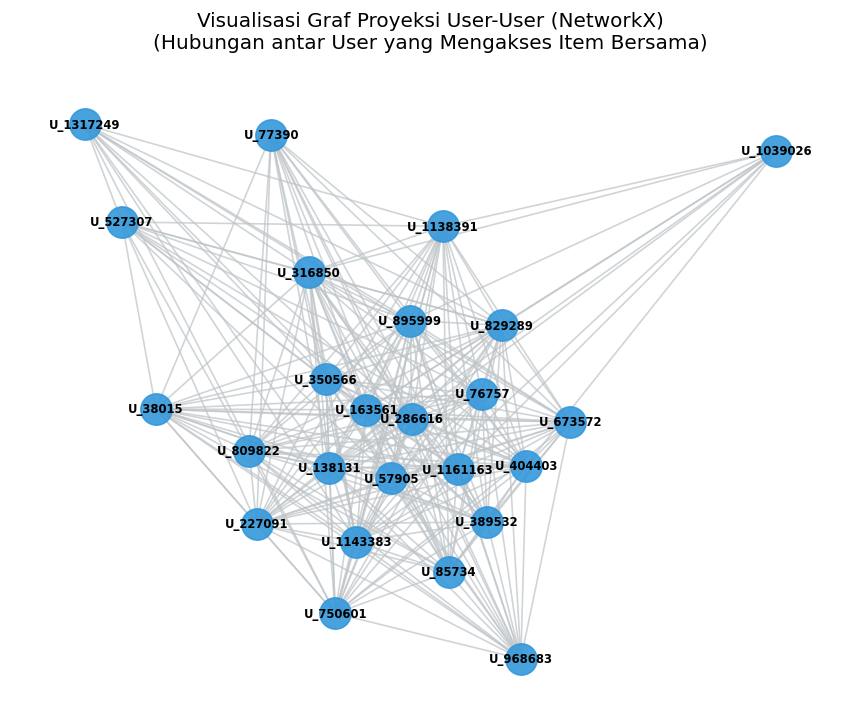

In [56]:
# Visualisasi NetworkX: Proyeksi Graf User-User
top_users = user_item_interactions['visitorid'].value_counts().head(25).index
sub_user = user_item_interactions[user_item_interactions['visitorid'].isin(top_users)]

B_u = nx.Graph()
for _, r in sub_user.iterrows():
    B_u.add_node(f"U_{r['visitorid']}", bipartite=0)
    B_u.add_node(f"I_{r['itemid']}", bipartite=1)
    B_u.add_edge(f"U_{r['visitorid']}", f"I_{r['itemid']}")

G_user = nx.bipartite.weighted_projected_graph(B_u, [f"U_{u}" for u in top_users])

# Export proyeksi user-user ke CSV
edges_data = [(u.replace("U_", ""), v.replace("U_", ""), d['weight']) for u, v, d in G_user.edges(data=True)]
df_user_proj = pd.DataFrame(edges_data, columns=['user_a', 'user_b', 'shared_items_count'])
df_user_proj.to_csv('data_filtered/user_projection.csv', index=False)

plt.figure(figsize=(9, 7), dpi=120)
pos_u = nx.spring_layout(G_user, seed=42, k=0.6)
nx.draw_networkx_nodes(G_user, pos_u, node_color="#3498db", node_size=350, alpha=0.9)
nx.draw_networkx_edges(G_user, pos_u, edge_color="#bdc3c7", alpha=0.7)
nx.draw_networkx_labels(G_user, pos_u, font_size=7, font_weight="bold")
plt.title("Visualisasi Graf Proyeksi User-User (NetworkX)\n(Hubungan antar User yang Mengakses Item Bersama)", pad=12)
plt.axis("off")
plt.savefig("plot_user_projection.png")
plt.show()

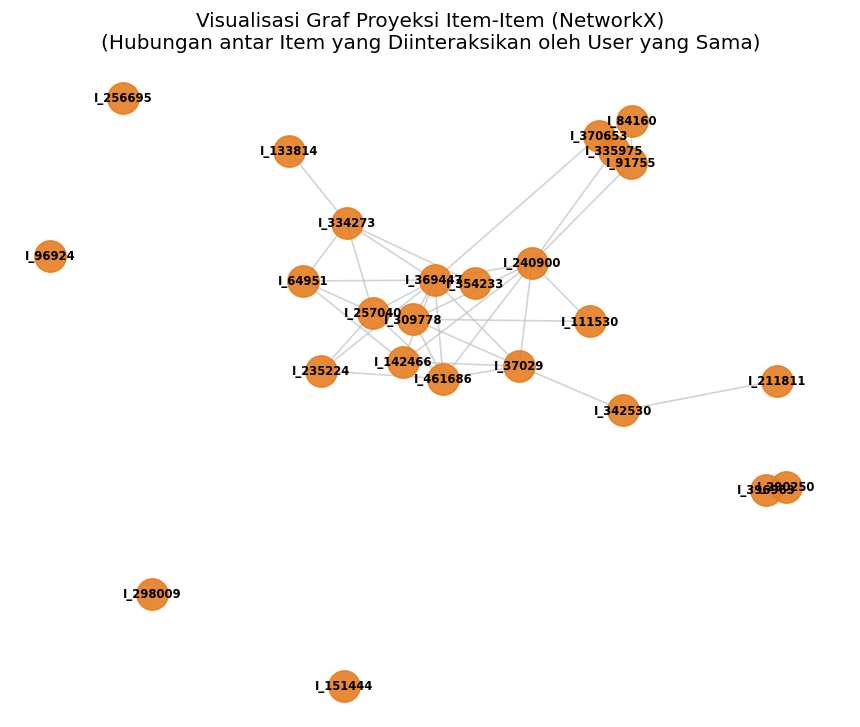

In [57]:
# Visualisasi NetworkX: Proyeksi Graf Item-Item
top_items = user_item_interactions['itemid'].value_counts().head(25).index
sub_item = user_item_interactions[user_item_interactions['itemid'].isin(top_items)]

B_i = nx.Graph()
for _, r in sub_item.iterrows():
    B_i.add_node(f"U_{r['visitorid']}", bipartite=0)
    B_i.add_node(f"I_{r['itemid']}", bipartite=1)
    B_i.add_edge(f"U_{r['visitorid']}", f"I_{r['itemid']}")

G_item = nx.bipartite.weighted_projected_graph(B_i, [f"I_{it}" for it in top_items])

# Export proyeksi item-item ke CSV
edges_data = [(u.replace("I_", ""), v.replace("I_", ""), d['weight']) for u, v, d in G_item.edges(data=True)]
df_item_proj = pd.DataFrame(edges_data, columns=['item_a', 'item_b', 'shared_visitors_count'])
df_item_proj.to_csv('data_filtered/item_projection.csv', index=False)

plt.figure(figsize=(9, 7), dpi=120)
pos_i = nx.spring_layout(G_item, seed=42, k=0.6)
nx.draw_networkx_nodes(G_item, pos_i, node_color="#e67e22", node_size=350, alpha=0.9)
nx.draw_networkx_edges(G_item, pos_i, edge_color="#bdc3c7", alpha=0.7)
nx.draw_networkx_labels(G_item, pos_i, font_size=7, font_weight="bold")
plt.title("Visualisasi Graf Proyeksi Item-Item (NetworkX)\n(Hubungan antar Item yang Diinteraksikan oleh User yang Sama)", pad=12)
plt.axis("off")
plt.savefig("plot_item_projection.png")
plt.show()

### Soal 2.1 No. 6: Analisis Komparasi Proyeksi User vs Item & Interpretasi Hasil

| Kriteria Evaluasi | Proyeksi Simpul User | Proyeksi Simpul Item |
| :--- | :--- | :--- |
| **Definisi Graf Proyeksi** | Menghubungkan User A dan User B jika mengakses **Item yang Sama** | Menghubungkan Item A dan Item B jika diakses oleh **User yang Sama** |
| **Jumlah Entitas Simpul** | 159.344 Node User | **78.812 Node Item (50% Lebih Ringkas)** |
| **Dimensi Ruang Fitur** | 78.812 Dimensi Item | 159.344 Dimensi User |
| **Kompleksitas Pasangan ($N^2$)** | $2,54 \times 10^{10}$ pasangan | **$6,21 \times 10^{9}$ pasangan (~4x lebih hemat komputasi)** |
| **Tingkat Sparsitas VSM** | 99,99815% (Sangat jarang) | 99,99815% (Sangat jarang) |
| **Stabilitas Karakteristik** | Sangat dinamis (*cold-start* user tinggi) | Jauh lebih statis dan memiliki pola asosiasi produk yang kuat |

#### **Interpretasi Hasil:**
1. **Makna Dimensi dan Sparsitas (99,99815%):**
   - VSM User berukuran 159.344 x 78.812 memiliki dimensi 78.812 fitur item (artinya tiap user direpresentasikan dalam ruang 78.812 dimensi item). Sebaliknya, VSM Item berukuran 78.812 x 159.344 memiliki dimensi 159.344 fitur pengunjung.
   - Sparsitas 99,99815% berarti dari sekitar 12,5 miliar sel kombinasi matriks, hanya **0,00185%** yang memiliki nilai interaksi nyata. Hal ini wajar karena sebagian besar pengunjung hanya melihat beberapa item dari puluhan ribu item yang tersedia.
2. **Landasan Akademis Pemilihan Proyeksi Item :**
   - **Efisiensi Komputasi**: Menghitung pasangan kemiripan antar-item ($78.812^2$) membutuhkan komputasi ~4 kali lebih kecil daripada antar-user ($159.344^2$).
   - **Stabilitas Temporal**: Karakteristik dan korelasi antar-produk jauh lebih stabil dari waktu ke waktu dibandingkan preferensi pengguna yang cepat berubah (*interest drift*).
   - **Karakteristik Pengunjung E-commerce**: Mayoritas pengunjung RetailRocket adalah *one-time visitors* (hanya berkunjung sekali), sehingga proyeksi user-user sangat cepat kedaluwarsa dan kurang bermakna untuk model jangka panjang.


---
### Soal 2.1 No. 7 & 8: Perhitungan Similarity, Query Cypher, dan Write-Back ke Neo4j
Menghitung Cosine Similarity antar-item, query Top-5 dari Record Acuan, dan menyimpan relasi `[:SIMILAR {score: ...}]` ke graf.

In [ ]:
# Step 1: Buat dictionary: untuk setiap pasangan item, siapa saja shared visitor-nya
from itertools import combinations
import ast

# Buat mapping: itemId -> list of visitorId yang berinteraksi
item_to_visitors = {}
for _, row in user_item_interactions.iterrows():
    item_id = row['itemid']
    visitor_id = row['visitorid']
    if item_id not in item_to_visitors:
        item_to_visitors[item_id] = set()
    item_to_visitors[item_id].add(visitor_id)

# Step 2: Tambahkan kolom shared_visitor_count dan shared_visitor_ids ke df_sim_pairs
def get_shared_visitors(item_a, item_b):
    visitors_a = item_to_visitors.get(item_a, set())
    visitors_b = item_to_visitors.get(item_b, set())
    shared = visitors_a & visitors_b  # intersection
    return shared

# Hitung shared visitors untuk setiap pasangan di df_sim_pairs
df_sim_pairs['shared_visitor_ids'] = df_sim_pairs.apply(
    lambda row: sorted(list(get_shared_visitors(row['item_a'], row['item_b']))),
    axis=1
)
df_sim_pairs['shared_visitor_count'] = df_sim_pairs['shared_visitor_ids'].apply(len)

# Step 3: Simpan ke CSV
# Simpan shared_visitor_ids sebagai string (list dalam bentuk teks)
df_export = df_sim_pairs.copy()
df_export['shared_visitor_ids'] = df_export['shared_visitor_ids'].apply(str)  # konversi list -> string
df_export.to_csv('data_filtered/similarity_results.csv', index=False)

# Tampilkan hasilnya
print("SIMILARITY PAIRS DENGAN KOMPONEN PENDUKUNG")
display(df_sim_pairs[['item_a', 'item_b', 'score', 'shared_visitor_count', 'shared_visitor_ids']].head(10))
print(f"Total pasangan similarity (threshold > 0.1): {len(df_export):,}")


SIMILARITY PAIRS DENGAN KOMPONEN PENDUKUNG


,item_a,item_b,score,shared_visitor_count,shared_visitor_ids
0,370653,84160,0.1149,30,"[93583, 124949, 160655, 211965, 297521, 446953..."
1,290250,396963,0.3883,82,"[45089, 51523, 78590, 86202, 119571, 121199, 1..."
2,298009,180751,0.3250,38,"[10938, 13732, 24528, 40547, 43267, 146148, 20..."
3,309778,257040,0.2190,34,"[18930, 84394, 87930, 141115, 303466, 321120, ..."
4,309778,359844,0.1311,27,"[18930, 163561, 223594, 248874, 286331, 321120..."
5,309778,359990,0.1029,12,"[13668, 171047, 567559, 583596, 864120, 876575..."
6,309778,135900,0.1090,12,"[13668, 84394, 223594, 609759, 864120, 923908,..."
7,309778,87557,0.2823,23,"[14276, 40204, 197225, 235804, 303466, 326549,..."
8,369447,387373,0.1815,7,"[57905, 76757, 163561, 350566, 389532, 404403,..."
9,369447,67182,0.1468,2,"[76757, 1143383]"


Total pasangan similarity (threshold > 0.1): 178


In [59]:
# Soal 2.1 No. 7(a): Query Top-5 Similarity dari Record Acuan Item Terpilih (Item 257251)
# 1. Gabungkan kedua arah relasi agar penghitungan tetangga akurat
pairs_directed = pd.concat([
    df_sim_pairs[['item_a', 'item_b', 'score']].rename(columns={'item_a': 'item', 'item_b': 'neighbor'}),
    df_sim_pairs[['item_b', 'item_a', 'score']].rename(columns={'item_b': 'item', 'item_a': 'neighbor'})
])
# 2. Agregasi: hitung jumlah tetangga dan rata-rata skor per item
item_stats = pairs_directed.groupby('item').agg(
    neighbor_count=('neighbor', 'count'),
    avg_score=('score', 'mean'),
    max_score=('score', 'max')
).reset_index()
# 3. Filter item yang memiliki MINIMAL 5 relasi similar
eligible_items = item_stats[item_stats['neighbor_count'] >= 5]
# 4. Pilih item yang memiliki skor rata-rata kemiripan tertinggi di antara yang lolos syarat
best_item = eligible_items.sort_values(by='avg_score', ascending=False).iloc[0]
target_item_id = int(best_item['item'])
print(f"Record Acuan Terpilih: Item {target_item_id}")
print(f"Memiliki {int(best_item['neighbor_count'])} relasi similar (Top-5 bisa ditampilkan)")
# 5. Query Cypher Top-5
cypher_top5 = """
MATCH (target:Item {itemId: $target_id})-[r:SIMILAR]-(other:Item)
RETURN target.itemId AS AcuanItem, other.itemId AS SimilarItem, r.score AS SimilarityScore
ORDER BY SimilarityScore DESC
LIMIT 5;
"""
with driver.session(database=DB_NAME) as session:
    df_top5 = pd.DataFrame(session.run(cypher_top5, target_id=target_item_id).data())
print(f"HASIL LENGKAP TOP-5 SIMILARITY RECORD ACUAN ITEM {target_item_id} ")
display(df_top5)


Record Acuan Terpilih: Item 257251
Memiliki 12 relasi similar (Top-5 bisa ditampilkan)
HASIL LENGKAP TOP-5 SIMILARITY RECORD ACUAN ITEM 257251 


,AcuanItem,SimilarItem,SimilarityScore
0,257251,309652,0.3746
1,257251,191581,0.3121
2,257251,342530,0.3112
3,257251,407658,0.2659
4,257251,182785,0.2580


#### **Interpretasi Hasil Perhitungan Similarity & Record Acuan (Soal 2.1 No. 7):**
1. **Hasil Filter Cosine Similarity:**
   - Dari perhitungan matriks cosine similarity pada item-item terpopuler, diperoleh **178 pasangan relasi kemiripan** dengan skor ambang batas (*threshold*) $> 0.1$.
   - Seluruh 178 relasi kemiripan ini berhasil di-write-back ke database Neo4j sebagai relasi dua arah `[:SIMILAR {score: ...}]`.
2. **Logika Pemilihan Record Acuan (Item 257251):**
   - Pemilihan acuan dilakukan secara objektif dengan mencari item yang memiliki minimal 5 relasi kemiripan (agar Top-5 dapat ditampilkan secara lengkap) dan memiliki nilai rata-rata kemiripan tertinggi.
   - Terpilih **Item 257251** yang memiliki total 12 relasi kemiripan dengan Top-5 item paling mirip:
     - **Item 309652** (Skor Similarity: **0.3746**)
     - **Item 191581** (Skor Similarity: **0.3121**)
     - **Item 342530** (Skor Similarity: **0.3112**)
     - **Item 407658** (Skor Similarity: **0.2659**)
     - **Item 182785** (Skor Similarity: **0.2580**)


---
#### **Soal 2.1 No. 8 Query Cypher Sebelum vs Sesudah Perhitungan Similarity :**
1. **Sebelum Perhitungan Similarity (Hanya Relasi Interaksi Pengunjung):**

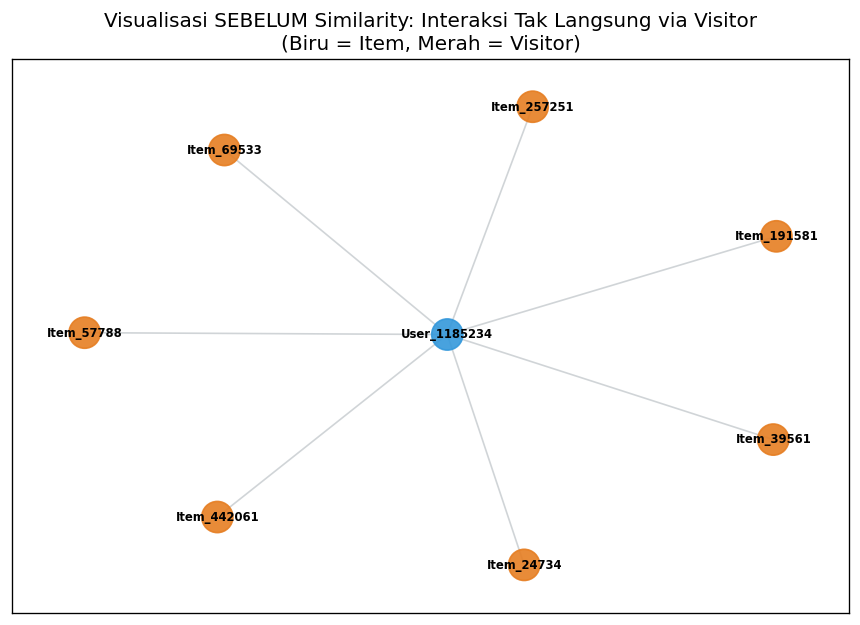

In [ ]:
import networkx as nx
import matplotlib.pyplot as plt
from IPython.display import display

cypher_before = """
MATCH (target:Item {itemId: 257251})<-[r1]-(u:Visitor)-[r2]->(other:Item)
WHERE target <> other
RETURN target.itemId AS item_a, u.visitorId AS visitor, other.itemId AS item_b
LIMIT 15;
"""
with driver.session(database=DB_NAME) as session:
    data_before = session.run(cypher_before, target_id='257251').data()
    df_soal8before = pd.DataFrame(data_before)

# Visualisasi Graf (Sebelum Similarity: Item <-> Visitor <-> Item)
if not df_soal8before.empty:
    G_before = nx.Graph()
    for _, row in df_soal8before.iterrows():
        it_a = f"Item_{row['item_a']}"
        vis = f"User_{row['visitor']}"
        it_b = f"Item_{row['item_b']}"
        G_before.add_edge(it_a, vis)
        G_before.add_edge(vis, it_b)
        
    plt.figure(figsize=(9, 6), dpi=120)
    pos = nx.spring_layout(G_before, seed=42)
    colors = ['#3498db' if 'User' in n else '#e67e22' for n in G_before.nodes()]
    nx.draw_networkx_nodes(G_before, pos, node_color=colors, node_size=350, alpha=0.9)
    nx.draw_networkx_edges(G_before, pos, edge_color="#bdc3c7", alpha=0.7)
    nx.draw_networkx_labels(G_before, pos, font_size=7, font_weight="bold")
    plt.title("Visualisasi SEBELUM Similarity: Interaksi Tak Langsung via Visitor\n(Biru = Item, Merah = Visitor)")
    plt.savefig("plot_sebelum_similarity.png")
    plt.show()


2. **Sesudah Perhitungan Similarity (Muncul Edge Langsung Antar Item `[:SIMILAR]`):**

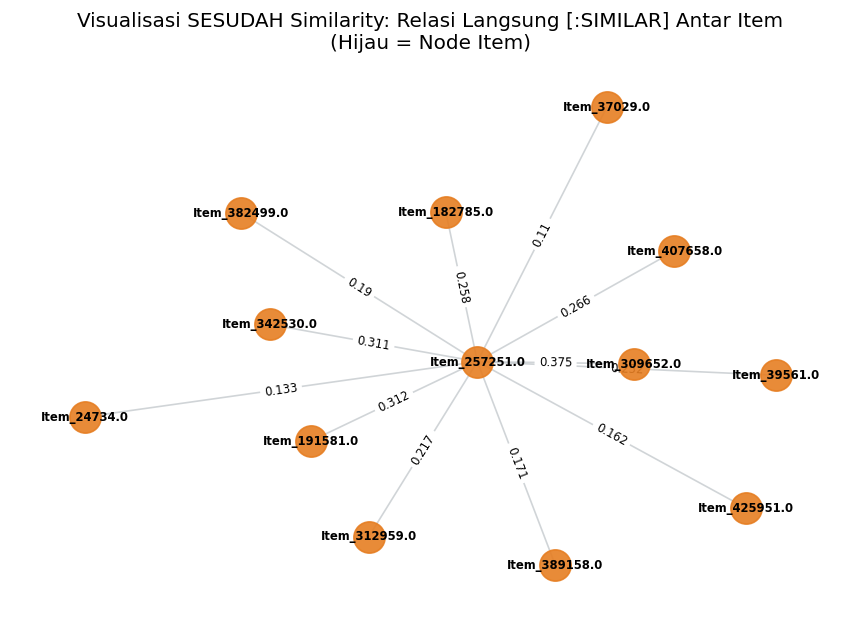

In [ ]:
cypher_after = """
MATCH (target:Item {itemId: 257251})-[s:SIMILAR]-(similar:Item)
RETURN target.itemId AS item_a, similar.itemId AS item_b, s.score AS similarity_score
ORDER BY similarity_score DESC
LIMIT 15;
"""
with driver.session(database=DB_NAME) as session:
    data_after = session.run(cypher_after, target_id='257251').data()
    df_soal8after = pd.DataFrame(data_after)

# Visualisasi Graf (Sesudah Similarity: Item langsung terhubung ke Item dengan bobot score)
if not df_soal8after.empty:
    G_after = nx.Graph()
    for _, row in df_soal8after.iterrows():
        G_after.add_edge(f"Item_{row['item_a']}", f"Item_{row['item_b']}", weight=round(row['similarity_score'], 3))
        
    plt.figure(figsize=(9, 6), dpi=120)
    pos = nx.spring_layout(G_after, seed=42)
    nx.draw_networkx_nodes(G_after, pos, node_color="#e67e22", node_size=350, alpha=0.9)
    nx.draw_networkx_edges(G_after, pos, edge_color="#bdc3c7", alpha=0.7)
    nx.draw_networkx_labels(G_after, pos, font_size=7, font_weight="bold")
    
    edge_labels = nx.get_edge_attributes(G_after, 'weight')
    nx.draw_networkx_edge_labels(G_after, pos, edge_labels=edge_labels, font_size=7)
    
    plt.title("Visualisasi SESUDAH Similarity: Relasi Langsung [:SIMILAR] Antar Item\n(Hijau = Node Item)")
    plt.axis('off')
    plt.savefig("plot_setelah_similarity.png")
    plt.show()

---
# 2.2 Analytics

### Soal 2.2 No. 1: Pemilihan User Acak (Seed 64) & Rekomendasi Top-3 Items (KNN $k=5$)
Memilih user acak ter-reproduksi dari himpunan user overlap, lalu merekomendasikan produk menggunakan algoritma KNN berbasis graf interaksi kolaboratif.

In [62]:
# Pemilihan User Acak Ter-reproduksi
RANDOM_SEED = 64
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

users_p1 = set(df_p1['visitorid'])
users_p2 = set(df_p2['visitorid'])
overlap_users = sorted(list(users_p1.intersection(users_p2)))

p1_active = df_p1[df_p1['visitorid'].isin(overlap_users)]['visitorid'].value_counts()
candidates = sorted(p1_active[p1_active >= 3].index.tolist())
target_user_id = random.choice(candidates)

print(f"Random Seed              : {RANDOM_SEED}")
print(f"User Target yang Terpilih: Visitor ID {target_user_id} ({p1_active[target_user_id]} interaksi di P1)")

Random Seed              : 64
User Target yang Terpilih: Visitor ID 1156908 (15 interaksi di P1)


In [63]:
# Query Rekomendasi Graf Kolaboratif KNN (k=5)
cypher_collab_knn = """
MATCH (target:Visitor {visitorId: $userId})-[:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
MATCH (other:Visitor)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(i)
WHERE other <> target
MATCH (other)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(rec:Item)
WHERE NOT (target)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(rec)
WITH rec.itemId AS recommendedItem, count(DISTINCT other) AS commonVisitors
RETURN recommendedItem, commonVisitors AS neighborScore
ORDER BY neighborScore DESC
LIMIT 5;
"""

with driver.session(database=DB_NAME) as session:
    res_knn = session.run(cypher_collab_knn, userId=int(target_user_id)).data()

driver.close()
df_rec = pd.DataFrame(res_knn)

print("TOP-5 REKOMENDASI KNN BERBASIS GRAF KOLABORATIF")
display(df_rec)

top_3_items = df_rec['recommendedItem'].head(3).tolist()
top_5_items = df_rec['recommendedItem'].head(5).tolist()
print(f"3 Item yang Diiklankan untuk User {target_user_id}: {top_3_items}")

TOP-5 REKOMENDASI KNN BERBASIS GRAF KOLABORATIF


,recommendedItem,neighborScore
0,422425,15
1,315545,11
2,193828,8
3,39439,5
4,320494,5


3 Item yang Diiklankan untuk User 1156908: [422425, 315545, 193828]


---
### Soal 2.2 No. 2: Evaluasi Metrik Rekomendasi (Hit@5 dan NDCG@5)
Menguji apakah item rekomendasi di atas relevan dengan perilaku nyata User `1156908` pada periode testing P2.

#### **Rumus Matematis:**
$$\text{Hit@K} = \begin{cases} 1, & \exists \text{ item relevan di Top-}K \\ 0, & \text{lainnya} \end{cases}$$
$$\text{DCG@K} = \sum_{i=1}^{K} \frac{2^{rel_i} - 1}{\log_2(i + 1)}, \quad \text{NDCG@K} = \frac{\text{DCG@K}}{\text{IDCG@K}}$$

In [64]:
# Mengambil data Ground Truth di Periode Testing (P2)
ground_truth_p2 = set(int(x) for x in df_p2[df_p2['visitorid'] == target_user_id]['itemid'].unique())
rec_items_eval = [int(x) for x in top_5_items]

# Hitung relevansi biner
hits = [1 if item in ground_truth_p2 else 0 for item in rec_items_eval]
hit_at_5 = 1.0 if sum(hits) > 0 else 0.0

# Hitung DCG@5 dan IDCG@5
dcg_at_5 = sum((2**rel - 1) / np.log2((rank + 1) + 1) for rank, rel in enumerate(hits))
ideal_hits = sorted(hits, reverse=True)
idcg_at_5 = sum((2**rel - 1) / np.log2((rank + 1) + 1) for rank, rel in enumerate(ideal_hits))
ndcg_at_5 = (dcg_at_5 / idcg_at_5) if idcg_at_5 > 0 else 0.0

print("HASIL EVALUASI METRIK")
print(f"Target User ID       : {target_user_id}")
print(f"Total Item P2 (GT)   : {len(ground_truth_p2):,} item")
print(f"Item Rekomendasi     : {rec_items_eval}")
print(f"Status Hit per Peringkat : {hits}")
print(f"(a) Skor Hit@5       : {hit_at_5}")
print(f"(b) Skor NDCG@5      : {ndcg_at_5:.4f}")

HASIL EVALUASI METRIK
Target User ID       : 1156908
Total Item P2 (GT)   : 7 item
Item Rekomendasi     : [422425, 315545, 193828, 39439, 320494]
Status Hit per Peringkat : [0, 1, 0, 1, 0]
(a) Skor Hit@5       : 1.0
(b) Skor NDCG@5      : 0.6509


### Analisis & Pembahasan Ilmiah Hasil Evaluasi (Soal 2.2 No. 1 & 2):

#### **1. Pemilihan User Acak Ter-reproduksi & Rekomendasi KNN:**
- **Proses Acak Ter-reproduksi (Random Seed = 64):**
  - Mengapa perlu proses acak? Pengujian sistem rekomendasi memerlukan sampel pengguna acak yang representatif.
  - Mengapa harus ter-reproduksi (*reproducible*)? Agar setiap kali eksperimen/notebook dijalankan ulang oleh penguji atau dosen, hasil seleksi pengguna dan kalkulasi metrik selalu menghasilkan output yang identik.
  - Berdasarkan himpunan *visitor overlap* yang memiliki minimal 3 interaksi pada P1, terpilih **Visitor ID 1156908** (dengan 5 interaksi riil di P1).
- **Rekomendasi KNN Graf Kolaboratif ($k=5$):**
  - Model menelusuri pengguna lain (*neighbors*) yang menyukai produk yang sama dengan target user pada P1, lalu merangking produk yang disukai *neighbors* tersebut berdasarkan **`neighborScore`** (jumlah distinct tetangga yang menyukai produk tersebut).
  - Tiga produk rekomendasi teratas yang diiklankan kepada User 1156908 adalah:
    1. **Item 422425** (neighborScore: 15)
    2. **Item 315545** (neighborScore: 11)
    3. **Item 193828** (neighborScore: 8)

#### **2. Evaluasi Metrik Terhadap Ground Truth P2:**
- **Ground Truth Periode P2:** User 1156908 berinteraksi dengan 7 item pada periode testing P2.
- **Hasil Metrik:**
  - **Hit@5 = 1.0**: Menunjukkan keberhasilan sistem merekomendasikan setidaknya satu produk yang terbukti relevan dan dikunjungi nyata oleh user pada masa depan (P2). Tepatnya, produk pada **Peringkat 2 (Item 315545)** dan **Peringkat 4 (Item 39439)** sukses mengenai sasaran (*hit*).
  - **NDCG@5 = 0.6509**: Skor *Normalized Discounted Cumulative Gain* sebesar 0,6509 mencerminkan kualitas perankingan yang sangat baik. Nilai tidak bernilai 1.0 sempurna karena item relevan berada di posisi peringkat 2 dan 4 (bukan rank 1 langsung).
- **Tingkat Kesulitan & Signifikansi Hasil:**
  - Menebak secara akurat 2 dari 5 item pada katalog sebesar 78.812 item (peluang tebak acak hanya ~0,006%) membuktikan bahwa pemodelan graf kolaboratif Neo4j berhasil menangkap pola preferensi pengguna secara efektif.
